In [1]:
# 8/6/26 olivia test code
import os
from jax import config
config.update("jax_enable_x64", True)
import sys
sys.path.append('/Users/olivialong/Desktop/UC Berkeley/Waller group/EncodingInformation/src')
sys.path.append('/Users/olivialong/Desktop/UC Berkeley/Waller group/EncodingInformation/lensless_imager')

In [2]:
from encoding_information.models import PixelCNN, PoissonNoiseModel # imports from encoding_information folder inside src
from encoding_information import estimate_information, extract_patches
from encoding_information.image_utils import add_noise

In [3]:
import inspect
from encoding_information.models import PoissonNoiseModel
print("summed over channels" if "spatial pixel" in inspect.getsource(PoissonNoiseModel) else "OLD version still loaded")

summed over channels


In [3]:
import tensorflow as tf
import tensorflow.keras as tfk

In [4]:
(x_train, y_train), (x_test, y_test) = tfk.datasets.cifar10.load_data() # 50k 32x32 color training images, 10k test images; labels are indexed 0-9

In [5]:
import jax.numpy as np
import numpy as onp

In [6]:
# for CIFAR10 dataset
assert x_train.shape == (50000, 32, 32, 3)
assert x_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

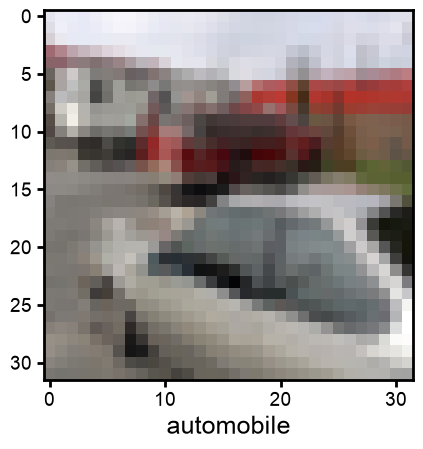

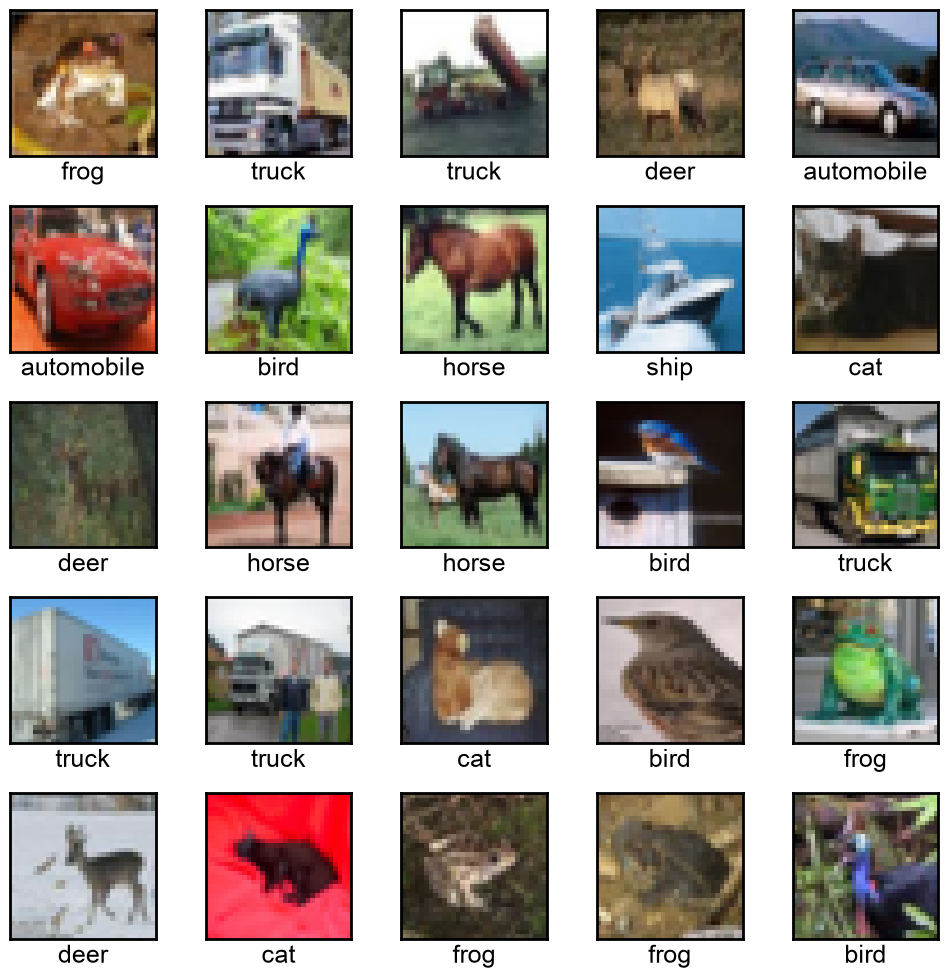

In [7]:
import matplotlib.pyplot as plt

# Class names (CIFAR-10 has 10 categories)
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

i = -1
plt.imshow(x_train[i])
plt.xlabel(class_names[y_train[i][0]])

# Plot a grid of sample images
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    # y_train labels come as [[label]], so we index [0]
    plt.xlabel(class_names[y_train[i][0]])

plt.tight_layout()
plt.show()


# generate fake data set of moving beads

bead_data shape: (3000, 64, 64)
photons  min/mean/max: 10.00 / 90.00 / 3133.21
corr(frame 0, frame 1):  0.874
corr(frame 0, frame 50): 0.002


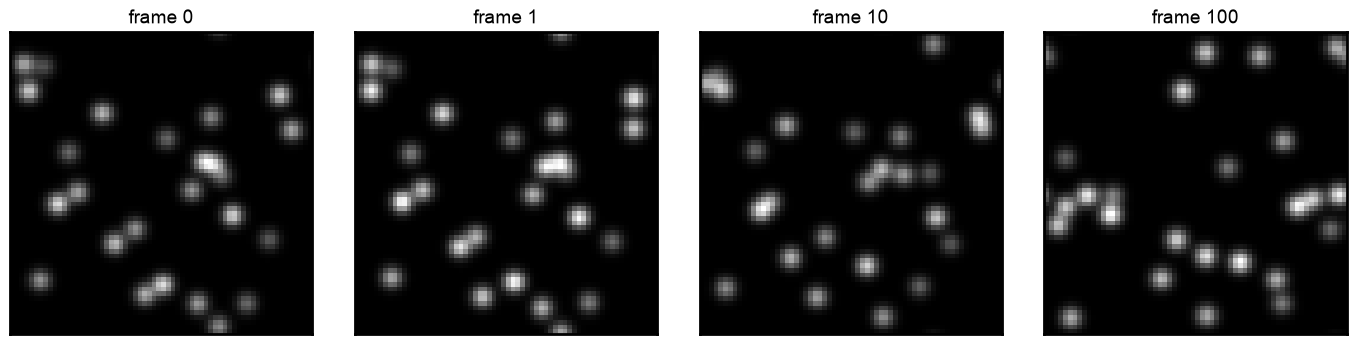

In [8]:
# generate fake data set of moving beads

def generate_moving_beads(num_time_frames, image_size=64, num_beads=25, bead_sigma=1.5,
                          diffusion_step=0.8, drift=(0.0, 0.0), seed=0):
    """
    Simulate beads undergoing constant drift + Brownian motion, rendered as Gaussian blobs.

    Parameters
    ----------
    num_time_frames : int
        Number of 2D frames. This becomes the sample axis that patches are drawn from.
    image_size : int
        Frames are (image_size, image_size).
    num_beads : int
        Beads in the field of view. Constant over time (periodic boundaries).
    bead_sigma : float
        Gaussian width of each bead, in pixels.
    diffusion_step : float
        Std dev of the per-frame random walk, in pixels. 0 = no Brownian motion.
    drift : (float, float)
        Constant per-frame velocity (row, col), in pixels.
    seed : int
        RNG seed.

    Returns
    -------
    frames : ndarray, shape (num_time_frames, image_size, image_size), float32
        Unnormalized intensity -- scaled to photons below.
    """
    rng = onp.random.default_rng(seed)

    # bead positions (row, col) and per-bead brightness
    pos = rng.uniform(0, image_size, size=(num_beads, 2))
    amps = rng.uniform(0.5, 1.5, size=num_beads)

    yy, xx = onp.meshgrid(onp.arange(image_size), onp.arange(image_size), indexing='ij')
    frames = onp.empty((num_time_frames, image_size, image_size), dtype=onp.float32)
    two_sig_sq = 2.0 * bead_sigma ** 2

    for t in range(num_time_frames):
        # periodic boundaries: shortest wrapped distance on each axis
        dy = onp.abs(yy[None] - pos[:, 0, None, None])
        dx = onp.abs(xx[None] - pos[:, 1, None, None])
        dy = onp.minimum(dy, image_size - dy)
        dx = onp.minimum(dx, image_size - dx)
        blobs = amps[:, None, None] * onp.exp(-(dy ** 2 + dx ** 2) / two_sig_sq)
        frames[t] = blobs.sum(axis=0)

        # advance: constant drift + random walk, wrapped back into the field of view
        pos += onp.asarray(drift)[None, :]
        pos += rng.normal(0.0, diffusion_step, size=pos.shape)
        pos %= image_size

    return frames


# ---- movie parameters ----
num_time_frames = 3000    # needs to be >> test_set_size so train/test frames don't overlap
image_size = 64
num_beads = 25
bead_sigma = 1.5
diffusion_step = 0.8      # pixels/frame of Brownian motion
drift = (0.15, 0.05)      # pixels/frame of constant flow

# these mirror the CIFAR path below; defined here so this cell runs standalone
photon_count = 80
bias = 10
seed_value = 2

frames = generate_moving_beads(num_time_frames, image_size=image_size, num_beads=num_beads,
                               bead_sigma=bead_sigma, diffusion_step=diffusion_step,
                               drift=drift, seed=seed_value)

# scale to a mean of photon_count photons, then add background bias
bead_data = frames / frames.mean() * photon_count + bias

print("bead_data shape:", bead_data.shape)
print("photons  min/mean/max: %.2f / %.2f / %.2f" % (bead_data.min(), bead_data.mean(), bead_data.max()))
print("corr(frame 0, frame 1):  %.3f" % onp.corrcoef(bead_data[0].ravel(), bead_data[1].ravel())[0, 1])
print("corr(frame 0, frame 50): %.3f" % onp.corrcoef(bead_data[0].ravel(), bead_data[50].ravel())[0, 1])

# preview a few frames
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, t in zip(axes, [0, 1, 10, 100]):
    ax.imshow(bead_data[t], cmap='gray')
    ax.set_title('frame %d' % t)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()


In [43]:
np.shape(bead_data)

(3000, 64, 64)

100%|██████████| 500/500 [00:00<00:00, 3671.83it/s]


patches:       (2000, 16, 16)
test_patches:  (500, 16, 16)


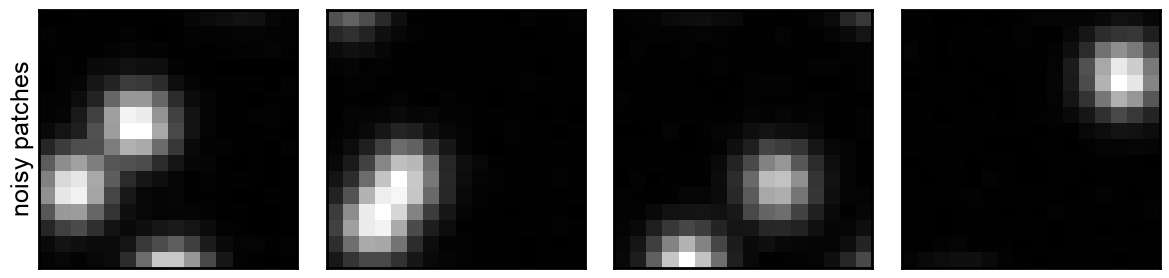

In [9]:
# patchify the bead movie -> feeds the PixelCNN / estimate_information cells below
# NOTE: this overwrites patches / test_patches / *_noisy / full_clean_patches.
# Run this INSTEAD of the CIFAR cells if you want the bead dataset.

# MI estimator parameters (same fast settings as the CIFAR path)
patch_size = 16
num_patches = 2000
test_set_size = 500
num_iters_per_epoch = 50
learning_rate = 1e-3
patience_val = 2
num_samples = 8

# split by FRAME so no patch appears in both train and test
patches = extract_patches(bead_data[:-test_set_size], patch_size=patch_size,
                          num_patches=num_patches, seed=seed_value, verbose=True)
test_patches = extract_patches(bead_data[-test_set_size:], patch_size=patch_size,
                               num_patches=test_set_size, seed=seed_value, verbose=True)

# clean patches for the Poisson conditional-entropy term
full_clean_patches = onp.concatenate([patches, test_patches])

# add Poisson noise to both splits
patches_noisy = add_noise(patches, seed=seed_value)
test_patches_noisy = add_noise(test_patches, seed=seed_value)

print("patches:      ", onp.shape(patches))
print("test_patches: ", onp.shape(test_patches))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, i in zip(axes, range(4)):
    ax.imshow(patches_noisy[i], cmap='gray')
    ax.set_xticks([]); ax.set_yticks([])
axes[0].set_ylabel('noisy patches')
plt.tight_layout()
plt.show()


# run pixelCNN on fake bead data

In [10]:
# run pixelCNN on fake bead data
# initialize pixelcnn 
pixel_cnn = PixelCNN() 

patience_val = 2

# fit pixelcnn to noisy patches. defaults to 10% val samples which will be 1k as desired. 
# using smaller lr this time and adding seeding, letting it go for full training time.
val_loss_history = pixel_cnn.fit(patches_noisy, seed=seed_value, learning_rate=learning_rate, do_lr_decay=False, steps_per_epoch=num_iters_per_epoch, 
                                 max_epochs = 5, patience=patience_val)

# generate samples, not necessary for MI sweeps
pixel_cnn_samples = pixel_cnn.generate_samples(num_samples=num_samples)
# # visualize samples
#plot_samples([pixel_cnn_samples], test_patches, model_names=['PixelCNN'])

/Users/olivialong/Desktop/UC Berkeley/Waller group/EncodingInformation/src/encoding_information/models/pixel_cnn.py:494: UserWarning: seed argument is deprecated. Use model_seed and data_seed instead
  warnings.warn("seed argument is deprecated. Use model_seed and data_seed instead")


Initial validation NLL: 692.65


Epoch 1: 100%|██████████| 50/50 [00:51<00:00,  1.03s/it]


Epoch 1: validation NLL: 5.60


Epoch 2: 100%|██████████| 50/50 [00:48<00:00,  1.03it/s]


...

Epoch 4: 100%|██████████| 50/50 [00:48<00:00,  1.03it/s]


Epoch 4: validation NLL: 4.69


Epoch 5: 100%|██████████| 50/50 [00:48<00:00,  1.02it/s]


Epoch 5: validation NLL: 4.24


Generating PixelCNN samples: 100%|██████████| 16/16 [00:33<00:00,  2.11s/it]


/var/folders/lc/ch_4h6155s5dx0ndjzbf4yph0000gn/T/ipykernel_89311/2194720029.py:2: DeprecationWarning: shape requires ndarray or scalar arguments, got <class 'list'> at position 0. In a future JAX release this will be an error.
  np.shape(val_loss_history)


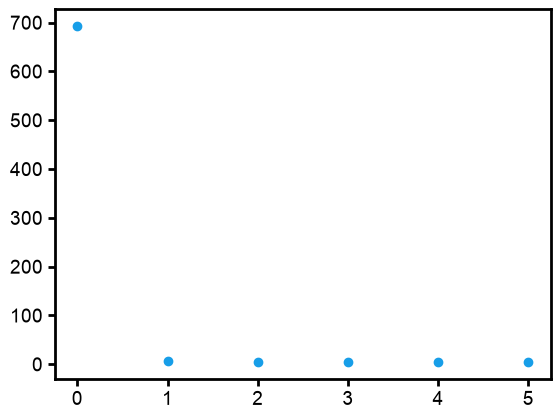

In [14]:
# visualize val_loss_history
np.shape(val_loss_history)
plt.scatter(range(6), val_loss_history)

In [45]:
#  instantiate noise model
noise_model = PoissonNoiseModel()
# estimate information using the fit pixelcnn and noise model, with clean data
pixel_cnn_info, pixel_cnn_lower_bound, pixel_cnn_upper_bound = estimate_information(pixel_cnn, noise_model, patches_noisy, 
                                                                                    test_patches_noisy, clean_data=full_clean_patches, 
                                                                                    confidence_interval=0.95)
print("PixelCNN estimated information: ", pixel_cnn_info)
print("PixelCNN lower bound: ", pixel_cnn_lower_bound)
print("PixelCNN upper bound: ", pixel_cnn_upper_bound)

Evaluating NLL: 16it [00:01, 12.66it/s]
Evaluating NLL: 500it [00:03, 143.63it/s]
Bootstrapping to compute confidence interval: 100%|██████████| 100/100 [00:00<00:00, 685.66it/s]


PixelCNN estimated information:  1.803514
PixelCNN lower bound:  1.7424856
PixelCNN upper bound:  1.8690381


(8, 16, 16)


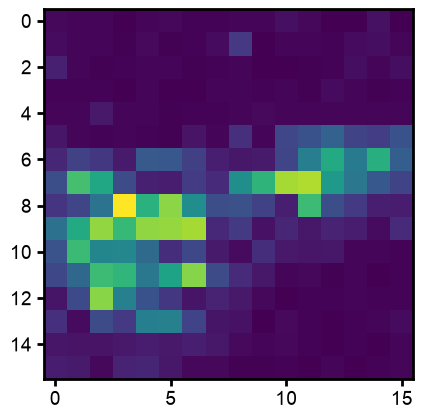

In [50]:
print(np.shape(pixel_cnn_samples))
ind = -1
plt.imshow(pixel_cnn_samples[ind])

In [19]:
# data processing code from leyla's 2024_10_23_pixelcnn_ file
from lensless_helpers import *

photon_count = 80;

seed_value = 2

data = onp.concatenate((x_train, x_test), axis=0)
labels = np.concatenate((y_train, y_test), axis=0)
data = data.astype(np.float32)

print("shape of data: ", data.shape)

# convert data to grayscale before converting to photons 
if len(data.shape) == 4:
    data = tf.image.rgb_to_grayscale(data).numpy()
    data = data.squeeze()
# convert to photons with mean value of photon_count 
data /= onp.mean(data)
data *= photon_count 
# make tiled data
random_data, random_labels = generate_random_tiled_data(data, labels, seed_value) # func from lensless_helpers.py


shape of data:  (60000, 32, 32, 3)


shape of random data:  (60000, 96, 96)
(60000, 32, 32)


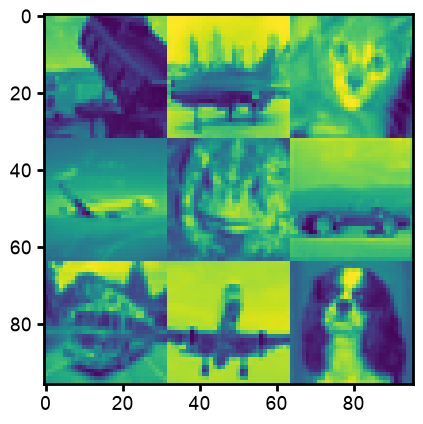

In [24]:
type(random_data)
print("shape of random data: ", np.shape(random_data))
print(np.shape(data))

i = 0
plt.imshow(random_data[i])

In [33]:
# using no psf pattern
psf_pattern = None

# MI estimator parameters 
patch_size = 32
num_patches = 10000
val_set_size = 1000
test_set_size = 1500 
num_samples = 8
learning_rate = 1e-3  # using 5x iterations per epoch, using smaller lr, and using less patience since it should be a smoother curve. 
num_iters_per_epoch = 500
patience_val = 20

# for faster run times
patch_size = 16              # from 32   — the big one, ~5x
num_patches = 2000           # from 10000
test_set_size = 500          # from 1500 — test set drives NLL + bootstrap cost
num_iters_per_epoch = 50     # from 500  — 10x

print("data.shape[-1]: ", data.shape[-1])

if psf_pattern is None:
    start_idx = data.shape[-1] // 2 # 16
    end_idx = data.shape[-1] // 2 - 1 # 15
    psf_data = random_data[:, start_idx:-end_idx, start_idx:-end_idx]
else:
    psf_data = convolved_dataset(psf_pattern, random_data) 


# add small bias to data 
bias = 10

psf_data += bias 
# make patches for training and testing splits, random patching 
patches = extract_patches(psf_data[:-test_set_size], patch_size=patch_size, num_patches=num_patches, seed=seed_value, verbose=True)
test_patches = extract_patches(psf_data[-test_set_size:], patch_size=patch_size, num_patches=test_set_size, seed=seed_value, verbose=True)  
# put all the clean patches together for use in MI estimatino function later
full_clean_patches = onp.concatenate([patches, test_patches])
# add noise to both sets 
patches_noisy = add_noise(patches, seed=seed_value)
test_patches_noisy = add_noise(test_patches, seed=seed_value)

data.shape[-1]:  32


100%|██████████| 500/500 [00:00<00:00, 3469.04it/s]


shape of psf_data[0]:  (65, 65)
shape of random data:  (96, 96)


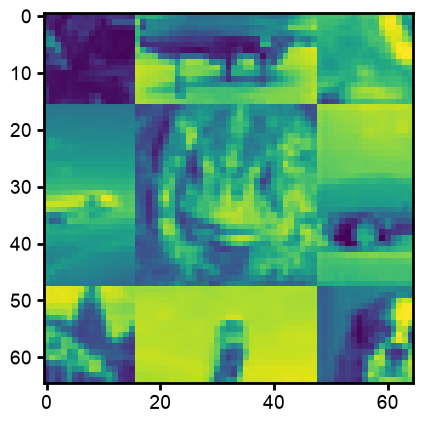

In [30]:
print("shape of psf_data[0]: ", np.shape(psf_data[0]))
print("shape of random data: ", np.shape(random_data[0]))
plt.imshow(psf_data[0])

In [26]:
start_idx

16

In [35]:
learning_rate
patience_val

20

# run pixelCNN on CIFAR10 data set

In [36]:
# initialize pixelcnn 
pixel_cnn = PixelCNN() 

patience_val = 2

# fit pixelcnn to noisy patches. defaults to 10% val samples which will be 1k as desired. 
# using smaller lr this time and adding seeding, letting it go for full training time.
val_loss_history = pixel_cnn.fit(patches_noisy, seed=seed_value, learning_rate=learning_rate, do_lr_decay=False, steps_per_epoch=num_iters_per_epoch, 
                                 max_epochs = 5, patience=patience_val)

# generate samples, not necessary for MI sweeps
pixel_cnn_samples = pixel_cnn.generate_samples(num_samples=num_samples)
# # visualize samples
plot_samples([pixel_cnn_samples], test_patches, model_names=['PixelCNN'])


/Users/olivialong/Desktop/UC Berkeley/Waller group/EncodingInformation/src/encoding_information/models/pixel_cnn.py:494: UserWarning: seed argument is deprecated. Use model_seed and data_seed instead
  warnings.warn("seed argument is deprecated. Use model_seed and data_seed instead")


Initial validation NLL: 12.63


Epoch 1: 100%|██████████| 50/50 [00:47<00:00,  1.05it/s]


Epoch 1: validation NLL: 4.37


Epoch 2: 100%|██████████| 50/50 [00:46<00:00,  1.08it/s]


...

Epoch 4: validation NLL: 4.21


Epoch 5: 100%|██████████| 50/50 [00:46<00:00,  1.08it/s]


Epoch 5: validation NLL: 4.19


Generating PixelCNN samples: 100%|██████████| 16/16 [00:32<00:00,  2.06s/it]


NameError: name 'plot_samples' is not defined

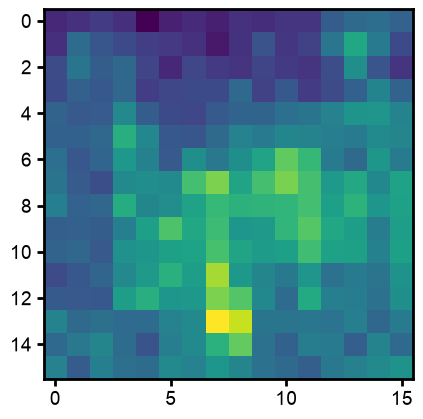

In [38]:
np.shape(pixel_cnn_samples)
plt.imshow(pixel_cnn_samples[0])

In [39]:
#  instantiate noise model
noise_model = PoissonNoiseModel()
# estimate information using the fit pixelcnn and noise model, with clean data
pixel_cnn_info, pixel_cnn_lower_bound, pixel_cnn_upper_bound = estimate_information(pixel_cnn, noise_model, patches_noisy, 
                                                                                    test_patches_noisy, clean_data=full_clean_patches, 
                                                                                    confidence_interval=0.95)
print("PixelCNN estimated information: ", pixel_cnn_info)
print("PixelCNN lower bound: ", pixel_cnn_lower_bound)
print("PixelCNN upper bound: ", pixel_cnn_upper_bound)

Evaluating NLL: 16it [00:01, 12.64it/s]
Evaluating NLL: 500it [00:03, 133.90it/s]
Bootstrapping to compute confidence interval: 100%|██████████| 100/100 [00:00<00:00, 438.70it/s]


PixelCNN estimated information:  0.7363266528045747
PixelCNN lower bound:  0.7188650870902852
PixelCNN upper bound:  0.7546598777461158


# Multichannel tests 1–3: time steps as channels (Mac settings)

Each sample is T frames of the same patch, shape (N, H, W, T), so `MultiChannelPixelCNN` models how the frames relate at each pixel. Requires the bead movie `bead_data` from the moving-beads cell above.

- **Test 1**: T = 1. Multichannel should match single-channel `PixelCNN`.
- **Test 2**: the same frame twice with independent noise. For Poisson noise this carries exactly the information of one frame at 2× photons.
- **Test 3**: two uncorrelated frames (100 apart). Should give about 2× the single-frame MI.

MI is reported in bits per pixel *location* (all channels of a pixel together). Since merging Leyla's update (leyla/main), `PoissonNoiseModel` sums H(Y|X) over channels per spatial pixel, matching the per-location NLL, so `mi_bits_per_location` and `estimate_information` should now agree. Both are printed as a check.

Mac settings are deliberately small: every fit is undertrained by the same amount, so judge the tests by direction and ratios, not exact values.

In [18]:
# ---- multichannel tests: setup ----
from encoding_information.models import MultiChannelPixelCNN

# Mac settings: small and fast. Identical for every fit so the comparisons are fair.
patch_size = 16
num_patches = 2000
test_set_size = 500          # number of test patches
test_frames = 500            # last 500 frames of the movie are held out for testing
num_iters_per_epoch = 50
max_epochs = 10 # not enough training for Test 2 below
max_epochs = 40
patience_val = 3
patience_val = 5
learning_rate = 1e-3
seed_value = 2

def stack_frames(movie, T, lag=1):
    """(num_frames, H, W) -> (num_frames - (T-1)*lag, H, W, T). Channel k is frame t + k*lag."""
    n = movie.shape[0] - (T - 1) * lag
    return onp.stack([movie[k*lag : k*lag + n] for k in range(T)], axis=-1)

def mi_bits_per_location(model, test_noisy, clean):
    """MI in bits per pixel location (all C channels of a pixel together).
    PoissonNoiseModel already sums H(Y|X) over channels per spatial pixel (leyla/main update),
    so it matches the per-location NLL directly. Before that update this needed (nll - C * h)."""
    nll = model.compute_negative_log_likelihood(test_noisy, verbose=False)   # nats per location
    h = PoissonNoiseModel().estimate_conditional_entropy(clean)             # nats per location, summed over channels
    return float((nll - h) / onp.log(2))

def fit(model, train_noisy):
    model.fit(train_noisy, learning_rate=learning_rate, steps_per_epoch=num_iters_per_epoch,
              max_epochs=max_epochs, patience=patience_val, model_seed=seed_value, data_seed=seed_value)
    return model

# split the movie by frame first, so no frame is in both train and test
train_movie = bead_data[:-test_frames]
test_movie  = bead_data[-test_frames:]

# one set of clean single-frame patches, shared by Tests 1 and 2 so they see identical scenes
clean_train = extract_patches(train_movie, patch_size=patch_size, num_patches=num_patches, seed=seed_value)
clean_test  = extract_patches(test_movie,  patch_size=patch_size, num_patches=test_set_size, seed=seed_value)
clean_all   = onp.concatenate([clean_train, clean_test])

results = {}
print("clean_train:", clean_train.shape, " clean_test:", clean_test.shape)

clean_train: (2000, 16, 16)  clean_test: (500, 16, 16)


In [16]:
# ---- Test 1: T = 1, multichannel should match single-channel ----
train_noisy = add_noise(clean_train, seed=10)
test_noisy  = add_noise(clean_test,  seed=11)

# (a) single-channel reference
pcnn_a = fit(PixelCNN(), train_noisy)
results['a: PixelCNN, 1 frame'] = mi_bits_per_location(pcnn_a, test_noisy, clean_all)

# (b) multichannel with one channel: the same data with a trailing channel axis
mc_b = fit(MultiChannelPixelCNN(), train_noisy[..., None])
results['b: MultiChannel, T=1'] = mi_bits_per_location(mc_b, test_noisy[..., None], clean_all[..., None])

for k, v in results.items():
    print(f"{k:45s} {v:.3f} bits/location")

Initial validation NLL: 719.56


Epoch 1: 100%|██████████| 50/50 [00:51<00:00,  1.03s/it]


Epoch 1: validation NLL: 5.61


Epoch 2: 100%|██████████| 50/50 [00:48<00:00,  1.03it/s]


Epoch 2: validation NLL: 5.23


...

Epoch 8: validation NLL: 3.79


Epoch 9: 100%|██████████| 50/50 [00:43<00:00,  1.15it/s]


Epoch 9: validation NLL: 3.76


Epoch 10: 100%|██████████| 50/50 [00:42<00:00,  1.17it/s]


Epoch 10: validation NLL: 3.73
a: PixelCNN, 1 frame                          1.045 bits/location
b: MultiChannel, T=1                          1.045 bits/location


In [17]:
# ---- Test 2: the same frame twice, independent Poisson noise on each copy ----
# Two noisy copies carry exactly the information of one copy at 2x photons
# (their sum is a sufficient statistic for Poisson noise), so (d) should match (c).

# (c) single-channel reference at 2x photons
train_noisy_2x = add_noise(2 * clean_train, seed=20)
test_noisy_2x  = add_noise(2 * clean_test,  seed=21)
pcnn_c = fit(PixelCNN(), train_noisy_2x)
results['c: PixelCNN, 1 frame at 2x photons'] = mi_bits_per_location(pcnn_c, test_noisy_2x, 2 * clean_all)

# (d) multichannel on [frame, frame]; add_noise draws independent noise for every element
clean_train_dup = onp.stack([clean_train, clean_train], axis=-1)
clean_test_dup  = onp.stack([clean_test,  clean_test],  axis=-1)
clean_all_dup   = onp.concatenate([clean_train_dup, clean_test_dup])
train_noisy_dup = add_noise(clean_train_dup, seed=22)
test_noisy_dup  = add_noise(clean_test_dup,  seed=23)
mc_d = fit(MultiChannelPixelCNN(), train_noisy_dup)
results['d: MultiChannel, same frame x2'] = mi_bits_per_location(mc_d, test_noisy_dup, clean_all_dup)

# the library's estimate, for comparison: should now match the value above
results['d (estimate_information)'] = float(estimate_information(
    mc_d, PoissonNoiseModel(), train_noisy_dup, test_noisy_dup, clean_data=clean_all_dup))

for k, v in results.items():
    print(f"{k:45s} {v:.3f} bits/location")

Initial validation NLL: 3114.24


Epoch 1: 100%|██████████| 50/50 [00:51<00:00,  1.03s/it]


Epoch 1: validation NLL: 9.03


Epoch 2: 100%|██████████| 50/50 [00:49<00:00,  1.01it/s]


Epoch 2: validation NLL: 7.18


...

Epoch 9: validation NLL: 45.21


Epoch 10: 100%|██████████| 50/50 [00:47<00:00,  1.05it/s]


Epoch 10: validation NLL: 41.72


Evaluating NLL: 16it [00:02,  7.40it/s]


a: PixelCNN, 1 frame                          1.045 bits/location
b: MultiChannel, T=1                          1.045 bits/location
c: PixelCNN, 1 frame at 2x photons            3.009 bits/location
d: MultiChannel, same frame x2                51.678 bits/location
d (estimate_information as-is)                56.024 bits/location


In [19]:
# (d) multichannel on [frame, frame]; add_noise draws independent noise for every element
clean_train_dup = onp.stack([clean_train, clean_train], axis=-1)
clean_test_dup  = onp.stack([clean_test,  clean_test],  axis=-1)
clean_all_dup   = onp.concatenate([clean_train_dup, clean_test_dup])
train_noisy_dup = add_noise(clean_train_dup, seed=22)
test_noisy_dup  = add_noise(clean_test_dup,  seed=23)
mc_d = fit(MultiChannelPixelCNN(), train_noisy_dup)
results['d: MultiChannel, same frame x2'] = mi_bits_per_location(mc_d, test_noisy_dup, clean_all_dup)

# the library's estimate, for comparison: should now match the value above
results['d (estimate_information)'] = float(estimate_information(
    mc_d, PoissonNoiseModel(), train_noisy_dup, test_noisy_dup, clean_data=clean_all_dup))

for k, v in results.items():
    print(f"{k:45s} {v:.3f} bits/location")

Initial validation NLL: 99219.59


Epoch 1: 100%|██████████| 50/50 [00:53<00:00,  1.06s/it]


Epoch 1: validation NLL: 265.11


Epoch 2: 100%|██████████| 50/50 [00:49<00:00,  1.00it/s]


Epoch 2: validation NLL: 130.86


...

Epoch 39: validation NLL: 13.20


Epoch 40: 100%|██████████| 50/50 [00:49<00:00,  1.02it/s]


Epoch 40: validation NLL: 13.07


Evaluating NLL: 16it [00:03,  4.91it/s]


d: MultiChannel, same frame x2                10.202 bits/location
d (estimate_information as-is)                14.549 bits/location


In [ ]:
# ---- Test 3: two frames 100 apart (uncorrelated), should give ~2x the single-frame MI ----
lag = 100
print("corr(frame 0, frame %d): %.3f" % (lag, onp.corrcoef(bead_data[0].ravel(), bead_data[lag].ravel())[0, 1]))

train_stack = stack_frames(train_movie, T=2, lag=lag)
test_stack  = stack_frames(test_movie,  T=2, lag=lag)
clean_train_ind = extract_patches(train_stack, patch_size=patch_size, num_patches=num_patches, seed=seed_value)
clean_test_ind  = extract_patches(test_stack,  patch_size=patch_size, num_patches=test_set_size, seed=seed_value)
clean_all_ind   = onp.concatenate([clean_train_ind, clean_test_ind])
train_noisy_ind = add_noise(clean_train_ind, seed=30)
test_noisy_ind  = add_noise(clean_test_ind,  seed=31)

mc_e = fit(MultiChannelPixelCNN(), train_noisy_ind)
results['e: MultiChannel, frames 100 apart'] = mi_bits_per_location(mc_e, test_noisy_ind, clean_all_ind)
results['e (estimate_information)'] = float(estimate_information(
    mc_e, PoissonNoiseModel(), train_noisy_ind, test_noisy_ind, clean_data=clean_all_ind))

for k, v in results.items():
    print(f"{k:45s} {v:.3f} bits/location")

In [ ]:
# ---- summary ----
a = results['a: PixelCNN, 1 frame']
print(f"{'fit':45s} {'bits/location':>14s} {'ratio to a':>11s}")
for k, v in results.items():
    print(f"{k:45s} {v:14.3f} {v / a:11.2f}")

print("""
What to look for (directions and ratios, not exact values, at Mac settings):
  Test 1: b ≈ a                      (ratio ≈ 1)
  Test 2: d ≈ c, and 1 < d/a < 2
  Test 3: e ≈ 2a                     (ratio ≈ 2)
  For d and e, the 'estimate_information' line should match the value above it:
  with the leyla/main noise models there is no longer a unit mismatch.""")